# Semiconductor Yield Prediction (Beginner-Friendly)

**Dataset:** UCI SECOM

**Goal:** Predict whether a semiconductor manufacturing record is Pass (`-1`) or Fail (`1`).

We will follow a simple sequence: load the data, look at it, prepare it, train classification models, compare them, and evaluate the best one.

**Main concepts included:** PCA, SMOTE, GridSearchCV, and classification models.

> Keep `uci-secom.csv` in the same folder as this notebook before running it.

## 1. Import the libraries

These libraries help us work with tables, make charts, prepare the data, and train machine learning models.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay, f1_score

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

print('Libraries imported successfully.')

Libraries imported successfully.


## 2. Load the UCI SECOM dataset

The CSV file contains sensor measurements and a `Pass/Fail` column. Each row represents one manufacturing record.

In [2]:
df = pd.read_csv('uci-secom.csv')

print('Dataset size:', df.shape)
df.head()

Dataset size: (1567, 592)


,Time,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,...,551,552,553,554,555,556,557,558,559,560,561,562,563,564,565,566,567,568,569,570,571,572,573,574,575,576,577,578,579,580,581,582,583,584,585,586,587,588,589,Pass/Fail
0,2008-07-19 11:55:00,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242,1.5005,0.0162,-0.0034,0.9455,202.4396,0.0,7.9558,414.8710,10.0433,0.9680,192.3963,12.5190,1.4026,-5419.00,2916.50,-4043.75,751.00,0.8955,1.7730,3.0490,64.2333,2.0222,0.1632,3.5191,83.3971,9.5126,50.6170,64.2588,49.3830,66.3141,86.9555,...,0.78,0.1827,5.7349,0.3363,39.8842,3.2687,1.0297,1.0344,0.4385,0.1039,42.3877,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,533.8500,2.1113,8.95,0.3157,3.0624,0.1026,1.6765,14.9509,NaN,NaN,NaN,NaN,0.5005,0.0118,0.0035,2.3630,NaN,NaN,NaN,NaN,-1
1,2008-07-19 12:32:00,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247,1.4966,-0.0005,-0.0148,0.9627,200.5470,0.0,10.1548,414.7347,9.2599,0.9701,191.2872,12.4608,1.3825,-5441.50,2604.25,-3498.75,-1640.25,1.2973,2.0143,7.3900,68.4222,2.2667,0.2102,3.4171,84.9052,9.7997,50.6596,64.2828,49.3404,64.9193,87.5241,...,1.33,0.2829,7.1196,0.4989,53.1836,3.9139,1.7819,0.9634,0.1745,0.0375,18.1087,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,535.0164,2.4335,5.92,0.2653,2.0111,0.0772,1.1065,10.9003,0.0096,0.0201,0.0060,208.2045,0.5019,0.0223,0.0055,4.4447,0.0096,0.0201,0.0060,208.2045,-1
2,2008-07-19 13:17:00,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241,1.4436,0.0041,0.0013,0.9615,202.0179,0.0,9.5157,416.7075,9.3144,0.9674,192.7035,12.5404,1.4123,-5447.75,2701.75,-4047.00,-1916.50,1.3122,2.0295,7.5788,67.1333,2.3333,0.1734,3.5986,84.7569,8.6590,50.1530,64.1114,49.8470,65.8389,84.7327,...,0.85,0.0857,7.1619,0.3752,23.0713,3.9306,1.1386,1.5021,0.3718,0.1233,24.7524,267.064,0.9032,1.10,0.6219,0.4122,0.2562,0.4119,68.8489,535.0245,2.0293,11.21,0.1882,4.0923,0.0640,2.0952,9.2721,0.0584,0.0484,0.0148,82.8602,0.4958,0.0157,0.0039,3.1745,0.0584,0.0484,0.0148,82.8602,1
3,2008-07-19 14:43:00,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217,1.4882,-0.0124,-0.0033,0.9629,201.8482,0.0,9.6052,422.2894,9.6924,0.9687,192.1557,12.4782,1.4011,-5468.25,2648.25,-4515.00,-1657.25,1.3137,2.0038,7.3145,62.9333,2.6444,0.2071,3.3813,84.9105,8.6789,50.5100,64.1125,49.4900,65.1951,86.6867,...,39.33,0.6812,56.9303,17.4781,161.4081,35.3198,54.2917,1.1613,0.7288,0.2710,62.7572,268.228,0.6511,7.32,0.1630,3.5611,0.0670,2.7290,25.0363,530.5682,2.0253,9.33,0.1738,2.8971,0.0525,1.7585,8.5831,0.0202,0.0149,0.0044,73.8432,0.4990,0.0103,0.0025,2.0544,0.0202,0.0149,0.0044,73.8432,-1
4,2008-07-19 15:22:00,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235,1.5031,-0.0031,-0.0072,0.9569,201.9424,0.0,10.5661,420.5925,10.3387,0.9735,191.6037,12.4735,1.3888,-5476.25,2635.25,-3987.50,117.00,1.2887,1.9912,7.2748,62.8333,3.1556,0.2696,3.2728,86.3269,8.7677,50.2480,64.1511,49.7520,66.1542,86.1468,...,1.98,0.4287,9.7608,0.8311,70.9706,4.9086,2.5014,0.9778,0.2156,0.0461,22.0500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,532.0155,2.0275,8.83,0.2224,3.1776,0.0706,1.6597,10.9698,NaN,NaN,NaN,NaN,0.4800,0.4766,0.1045,99.3032,0.0202,0.0149,0.0044,73.8432,-1


## 3. Understand the data

Check the column names, missing values, and the number of Pass and Fail records. This helps us understand what needs to be prepared.

In [3]:
print('Missing values in the dataset:', df.isnull().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
print('Pass/Fail counts:')
print(df['Pass/Fail'].value_counts())

Missing values in the dataset: 41951


Duplicate rows: 0
Pass/Fail counts:
Pass/Fail
-1    1463
 1     104
Name: count, dtype: int64


## 4. Visualize Pass and Fail records

The dataset contains many more Pass records than Fail records. The bar chart makes this class imbalance easy to see.

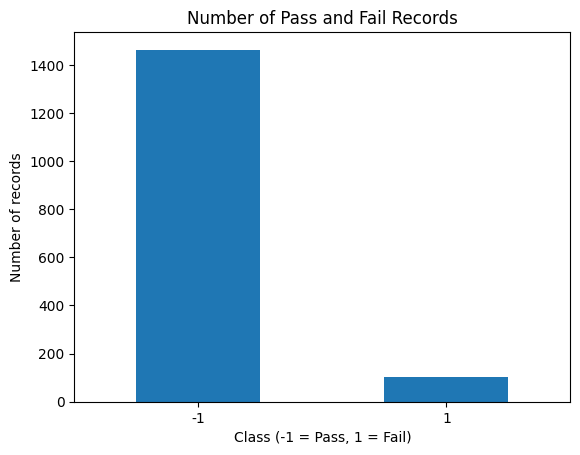

In [4]:
df['Pass/Fail'].value_counts().sort_index().plot(kind='bar')
plt.title('Number of Pass and Fail Records')
plt.xlabel('Class (-1 = Pass, 1 = Fail)')
plt.ylabel('Number of records')
plt.xticks(rotation=0)
plt.show()

## 5. Separate the input data and target

`X` contains the sensor measurements used to make predictions. `y` contains the answer we want the model to learn. We leave out `Time` because it is a timestamp, not a sensor measurement.

In [5]:
X = df.drop(columns=['Pass/Fail', 'Time'])
y = df['Pass/Fail']

print('Input data shape:', X.shape)
print('Target shape:', y.shape)

Input data shape: (1567, 590)
Target shape: (1567,)


## 6. Split into training and testing data

The model learns from the training data. The test data is kept separate until the final evaluation. `stratify=y` keeps the Pass/Fail proportions similar in both groups.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Training records:', X_train.shape[0])
print('Testing records:', X_test.shape[0])

Training records: 1253
Testing records: 314


## 7. Prepare the data, apply PCA, and use SMOTE

The steps below are placed in one pipeline so they are learned only from the training part of each cross-validation split:

1. **Imputer:** fills missing values with the median.
2. **Scaler:** puts sensor values on a similar scale.
3. **PCA:** combines the sensor information into fewer principal components while keeping 95% of the variation.
4. **SMOTE:** creates extra examples of the less common Fail class during model training.

Keeping these steps in the pipeline helps prevent information from the test data leaking into training.

In [7]:
print('Training class counts before SMOTE:')
print(y_train.value_counts())

# The preprocessing and SMOTE steps will be added to each model below.

Training class counts before SMOTE:
Pass/Fail
-1    1170
 1      83
Name: count, dtype: int64


## 8. Train classification models with GridSearchCV

We will compare three common classification models:

- **Logistic Regression:** a simple starting model for classification.
- **Random Forest:** combines several decision trees.
- **Support Vector Machine (SVM):** finds a boundary between the classes.

GridSearchCV tries the parameter values listed below and uses 3-fold cross-validation to select the best settings. The score focuses on identifying the Fail class (F1-score).

In [8]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000),
    'Random Forest': RandomForestClassifier(random_state=42),
    'SVM': SVC()
}

parameter_grids = {
    'Logistic Regression': {'model__C': [0.1, 1]},
    'Random Forest': {'model__n_estimators': [100], 'model__max_depth': [None, 10]},
    'SVM': {'model__C': [0.1, 1], 'model__kernel': ['rbf']}
}

results = []
best_models = {}

for name, model in models.items():
    print('Training:', name)

    pipeline = ImbPipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=0.95)),
        ('smote', SMOTE(random_state=42)),
        ('model', model)
    ])

    search = GridSearchCV(
        pipeline, parameter_grids[name], cv=3, scoring='f1', n_jobs=-1
    )
    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_
    predictions = search.predict(X_test)

    results.append({
        'Model': name,
        'Best CV F1': search.best_score_,
        'Test Accuracy': accuracy_score(y_test, predictions),
        'Test Fail F1': f1_score(y_test, predictions, pos_label=1),
        'Best Parameters': search.best_params_
    })

    print('Best parameters:', search.best_params_)
    print('Test Fail F1:', round(f1_score(y_test, predictions, pos_label=1), 3))
    print()

Training: Logistic Regression


Best parameters: {'model__C': 1}
Test Fail F1: 0.119

Training: Random Forest


Best parameters: {'model__max_depth': 10, 'model__n_estimators': 100}
Test Fail F1: 0.071

Training: SVM


Best parameters: {'model__C': 0.1, 'model__kernel': 'rbf'}
Test Fail F1: 0.12



## 9. Compare the models

This table compares the cross-validation F1-score, test accuracy, and Fail-class F1-score. Accuracy alone is not enough because most records belong to the Pass class.

In [9]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values('Test Fail F1', ascending=False)
results_df

,Model,Best CV F1,Test Accuracy,Test Fail F1,Best Parameters
2,SVM,0.178120,0.859873,0.120000,"{'model__C': 0.1, 'model__kernel': 'rbf'}"
0,Logistic Regression,0.163030,0.812102,0.119403,{'model__C': 1}
1,Random Forest,0.040404,0.917197,0.071429,"{'model__max_depth': 10, 'model__n_estimators'..."


## 10. Plot the model comparison

The chart compares how well each model identifies the Fail class. A higher Fail F1-score is better for balancing Fail precision and Fail recall.

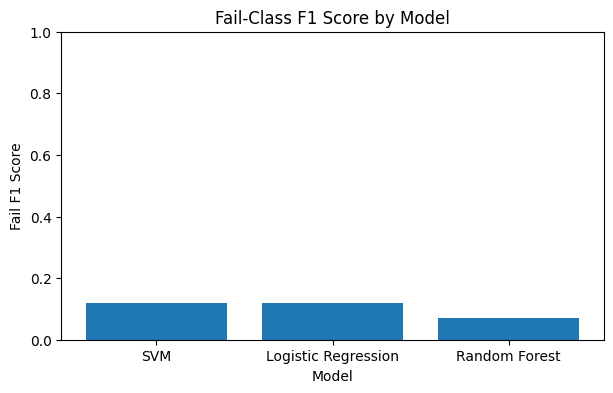

In [10]:
plt.figure(figsize=(7, 4))
plt.bar(results_df['Model'], results_df['Test Fail F1'])
plt.title('Fail-Class F1 Score by Model')
plt.xlabel('Model')
plt.ylabel('Fail F1 Score')
plt.ylim(0, 1)
plt.show()

## 11. Evaluate the best model

We select the model with the highest Fail-class F1-score on the test set. The classification report shows precision, recall, and F1-score for both classes. The confusion matrix shows the number of correct and incorrect predictions.

Selected model: SVM
Test accuracy: 0.86

Classification report:
              precision    recall  f1-score   support

        Pass       0.94      0.91      0.92       293
        Fail       0.10      0.14      0.12        21

    accuracy                           0.86       314
   macro avg       0.52      0.53      0.52       314
weighted avg       0.88      0.86      0.87       314



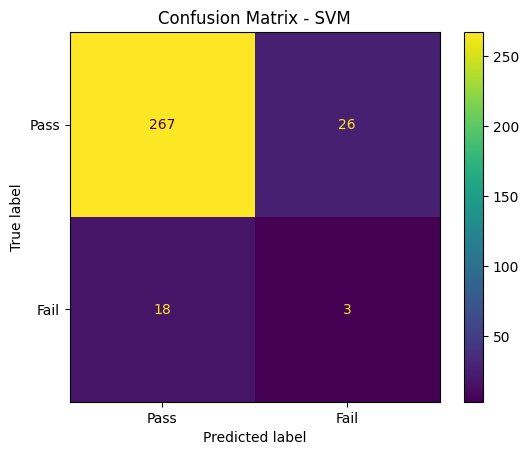

In [11]:
best_model_name = results_df.iloc[0]['Model']
best_model = best_models[best_model_name]
best_predictions = best_model.predict(X_test)

print('Selected model:', best_model_name)
print('Test accuracy:', round(accuracy_score(y_test, best_predictions), 3))
print('\nClassification report:')
print(classification_report(y_test, best_predictions, labels=[-1, 1], target_names=['Pass', 'Fail'], zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, best_predictions, labels=[-1, 1], display_labels=['Pass', 'Fail']
)
plt.title('Confusion Matrix - ' + best_model_name)
plt.show()

## 12. Understand the PCA result

PCA reduces the number of sensor measurements into a smaller set of principal components. The number below shows how many components were needed to keep 95% of the variation in the training data.

In [12]:
pca_step = best_model.named_steps['pca']
print('Original number of sensor features:', X_train.shape[1])
print('Number of PCA components kept:', pca_step.n_components_)
print('Explained variation kept:', round(pca_step.explained_variance_ratio_.sum(), 3))

Original number of sensor features: 590
Number of PCA components kept: 166
Explained variation kept: 0.95


## 13. Conclusion

In this project, we used the UCI SECOM dataset to predict semiconductor manufacturing outcomes. We prepared missing sensor values, scaled the data, used PCA to reduce the number of features, and used SMOTE to address the imbalance between Pass and Fail records. We trained Logistic Regression, Random Forest, and SVM classifiers and used GridSearchCV to find suitable model settings.

The best model should be judged especially by its ability to identify Fail records, not by accuracy alone. A low Fail recall means that some defective records are still missed. This is an important limitation to discuss honestly.

## 14. Save the best model

The saved pipeline includes data preparation, PCA, SMOTE configuration, and the trained classifier. It can be loaded later to make predictions on new records with the same sensor columns.

In [13]:
import joblib

joblib.dump(best_model, 'semiconductor_yield_model.pkl')
print('Model saved as semiconductor_yield_model.pkl')

Model saved as semiconductor_yield_model.pkl
